# Baseline BirdNET Testing: The Full BirdNET Model Without Training

This notebook tests BirdNET (version 2.4) as it is distributed, with no training on the project data:
1. Cuts every clean 3.0-second window from its original recording at 48 kHz, the input BirdNET expects.
2. Runs the full BirdNET model and reads the confidence of its own *Philippine Eagle* class.
3. Calls a window "eagle" when that confidence is at least 0.50, the threshold used for the other models.
4. Evaluates on the same test subsets as the other models: the recording split and the three held-out-site splits.

Two points to keep in mind when reading the results:
- BirdNET is trained on public archives that include the Macaulay Library, the source of these recordings, so some of the test recordings may have been part of its training data.
- The 0.50 threshold is the convention of this project and not a BirdNET setting. ROC-AUC and PR-AUC do not depend on it.

## 1. Imports and Configuration

In [1]:
import re
import time
import warnings
from pathlib import Path

import audioread
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from birdnetlib.analyzer import LABEL_PATH, MODEL_PATH
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Random seed for reproducibility (the same seed gives the same subsets as the other notebooks)
SEED = 42
np.random.seed(SEED)

# Directory paths
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
CM_DIR = OUTPUTS_DIR / "confusion-matrices"
STATISTICS_DIR = OUTPUTS_DIR / "statistics"
for folder in (FIGURES_DIR, CM_DIR, STATISTICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_DIR = PROJECT_ROOT / "data"
META_3S_PATH = DATA_DIR / "preprocessed" / "3-seconds" / "metadata.csv"
RAW_DIR = DATA_DIR / "raw"
RAW_AUDIO_DIRS = {
    "eagle-audios": RAW_DIR / "eagle-audios" / "audios",
    "hard-negatives": RAW_DIR / "hard-negatives" / "audios",
}

# Saved BirdNET scores. Delete this file to run BirdNET on the windows again.
SCORES_PATH = OUTPUTS_DIR / "birdnet-species-scores.csv"

# BirdNET input: 3.0 seconds at 48 kHz
BIRDNET_SR = 48000
BIRDNET_WINDOW_SAMPLES = int(3.0 * BIRDNET_SR)  # 144,000 samples

# The BirdNET class that is read as the eagle score, and the decision threshold
EAGLE_SCIENTIFIC_NAME = "Pithecophaga jefferyi"
DECISION_THRESHOLD = 0.50

MINOR_SITES = ["Bukidnon", "Davao Oriental", "Agusan del Sur", "Misamis Oriental"]

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:      {PROJECT_ROOT}")
print(f"Window metadata:   {META_3S_PATH}")
print(f"BirdNET model:     {MODEL_PATH}")
print(f"Outputs directory: {OUTPUTS_DIR}")


I0000 00:00:1791820910.757149  291872 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791820910.796558  291872 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791820912.220043  291872 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root:      /home/fumei/Documents/MachineLearning/EagleSoundClassification
Window metadata:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/metadata.csv
BirdNET model:     /home/fumei/Documents/MachineLearning/EagleSoundClassification/.venv/lib/python3.13/site-packages/birdnetlib/models/analyzer/BirdNET_GLOBAL_6K_V2.4_Model_FP32.tflite
Outputs directory: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/baseline-birdnet-testing/outputs


## 2. Load the 3.0-Second Window Metadata

In [2]:
# Original (unaugmented) windows, without the ones that touch an ambiguous annotation
df_meta = pd.read_csv(META_3S_PATH)
df_clean = df_meta[~df_meta["has_ambiguous"]].copy().reset_index(drop=True)
df_clean["slice_id"] = df_clean["file_name"].apply(lambda f: Path(f).stem)
df_clean["is_augmented"] = False  # BirdNET is not trained here, so no augmented copies are used
df_clean["group"] = np.where(
    df_clean["label"] == 1, "Eagle",
    np.where(df_clean["dataset_source"] == "eagle-audios", "Ambient", "Hard negative"),
)

print(f"Clean 3.0-second windows: {len(df_clean):,} from {df_clean['source_audio'].nunique()} recordings")
print(df_clean["group"].value_counts().to_string())


Clean 3.0-second windows: 11,084 from 562 recordings
group
Ambient          5262
Eagle            3337
Hard negative    2485


## 3. Data Partition Functions (Same as the Other Model Notebooks)

In [3]:
def create_recording_split(df_clean, train_ratio=0.70, val_ratio=0.15, random_state=SEED):
    """
    Recording-level split: every source recording is assigned to exactly one subset.
    1. Recordings are grouped into strata: eagle recordings by site (the two main sites, and the
       smaller sites together) and hard-negative recordings by species.
    2. Within each stratum the recordings are shuffled and divided into Train, Val, and Test.
    3. All clips of a recording follow it. Augmented clips are kept only for Train recordings.
    Returns the train, val, and test indices and a table with the subset of every recording.
    """
    df_orig = df_clean[~df_clean["is_augmented"]]
    recordings = df_orig.groupby("source_audio").agg(
        dataset_source=("dataset_source", "first"),
        site=("site", "first"),
        species=("species", "first"),
        clips=("label", "size"),
        eagle_clips=("label", "sum"),
    ).reset_index()

    main_sites = {"Davao del Sur", "Cotabato"}
    is_eagle_recording = recordings["dataset_source"] == "eagle-audios"
    recordings["stratum"] = np.where(
        is_eagle_recording,
        "eagle | " + recordings["site"].where(recordings["site"].isin(main_sites), "other sites"),
        "hard negative | " + recordings["species"],
    )

    rng = np.random.default_rng(random_state)
    test_ratio = 1.0 - train_ratio - val_ratio
    assignment = {}
    for _, group in recordings.groupby("stratum", sort=True):
        names = rng.permutation(np.sort(group["source_audio"].values))
        n = len(names)
        n_test = max(1, int(round(n * test_ratio))) if n >= 3 else 0
        n_val = max(1, int(round(n * val_ratio))) if n >= 3 else 0
        for position, name in enumerate(names):
            assignment[name] = "test" if position < n_test else ("val" if position < n_test + n_val else "train")

    recordings["split"] = recordings["source_audio"].map(assignment)
    clip_split = df_clean["source_audio"].map(assignment).values
    is_aug = df_clean["is_augmented"].values

    train_idx = np.where(clip_split == "train")[0]
    val_idx = np.where((clip_split == "val") & ~is_aug)[0]
    test_idx = np.where((clip_split == "test") & ~is_aug)[0]
    return train_idx, val_idx, test_idx, recordings


def split_overlap_matrices(df_clean, train_idx, val_idx, test_idx):
    """Recordings and clips shared between each pair of subsets. The diagonal holds the size of each subset."""
    names = ["Train", "Val", "Test"]
    sources = df_clean["source_audio"].values
    clip_sets = [set(np.asarray(idx).tolist()) for idx in (train_idx, val_idx, test_idx)]
    recording_sets = [set(sources[np.asarray(idx)]) for idx in (train_idx, val_idx, test_idx)]
    recording_overlap = pd.DataFrame([[len(a & b) for b in recording_sets] for a in recording_sets], index=names, columns=names)
    clip_overlap = pd.DataFrame([[len(a & b) for b in clip_sets] for a in clip_sets], index=names, columns=names)
    return recording_overlap, clip_overlap


def assert_no_leakage(df_clean, train_idx, val_idx, test_idx):
    """Stop with an error if a recording or a clip is in two subsets, or if an augmented clip is outside Train."""
    recording_overlap, clip_overlap = split_overlap_matrices(df_clean, train_idx, val_idx, test_idx)
    off_diagonal = lambda m: int(m.values.sum() - np.trace(m.values))
    assert off_diagonal(recording_overlap) == 0, f"Recordings shared between subsets:\n{recording_overlap}"
    assert off_diagonal(clip_overlap) == 0, f"Clips shared between subsets:\n{clip_overlap}"

    is_aug = df_clean["is_augmented"].values
    sources = df_clean["source_audio"].values
    assert not is_aug[val_idx].any(), "Augmented clips found in Val"
    assert not is_aug[test_idx].any(), "Augmented clips found in Test"
    train_original_recordings = set(sources[train_idx][~is_aug[train_idx]])
    assert set(sources[train_idx][is_aug[train_idx]]) <= train_original_recordings, "Augmented clip from a recording outside Train"
    return recording_overlap, clip_overlap


def create_loso_split(df_clean, holdout_site, val_ratio=0.15, random_state=SEED):
    """
    Leak-free Leave-One-Site-Out (LOSO) split:
    1. Test set consists ONLY of unaugmented samples from the holdout site (one site name or a list of sites).
    2. Remaining sites form the train pool (unaugmented).
    3. GroupShuffleSplit partitions train pool into Train and Val by source_audio.
    4. Augmented samples from training sources are injected ONLY into Train.
    5. Guarantees Val and Test have 0 augmented samples.
    """
    holdout_sites = [holdout_site] if isinstance(holdout_site, str) else list(holdout_site)

    orig_indices = np.where(~df_clean["is_augmented"].values)[0]
    df_orig = df_clean.iloc[orig_indices].reset_index(drop=True)

    test_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site in holdout_sites]
    test_idx = [orig_indices[i] for i in test_orig_sub_idx]

    pool_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site not in holdout_sites]
    df_pool = df_orig.iloc[pool_orig_sub_idx].reset_index(drop=True)
    pool_indices = [orig_indices[i] for i in pool_orig_sub_idx]

    gss = GroupShuffleSplit(n_splits=1, test_size=val_ratio, random_state=random_state)
    tr_sub, val_sub = next(gss.split(df_pool, df_pool["label"], df_pool["source_audio"]))

    orig_train_idx = [pool_indices[i] for i in tr_sub]
    val_idx = [pool_indices[i] for i in val_sub]

    train_sources = set(df_pool.iloc[tr_sub]["source_audio"])
    aug_indices = np.where(df_clean["is_augmented"].values)[0]
    train_aug_idx = [i for i in aug_indices if df_clean.iloc[i]["source_audio"] in train_sources]

    train_idx = orig_train_idx + train_aug_idx
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


## 4. Build the Test Subsets and Check for Leakage

In [4]:
# Only the test subsets are used here. The train and validation subsets are built so that the
# test subsets are the same ones the other models were tested on.
SPLITS = {}

train_idx, val_idx, test_idx, df_recordings = create_recording_split(df_clean)
assert_no_leakage(df_clean, train_idx, val_idx, test_idx)
SPLITS["Recording Split"] = test_idx

for split_name, holdout in [
    ("LOSO - Davao del Sur", "Davao del Sur"),
    ("LOSO - Cotabato", "Cotabato"),
    ("Minor Sites Held Out", MINOR_SITES),
]:
    train_idx, val_idx, test_idx = create_loso_split(df_clean, holdout_site=holdout, val_ratio=0.15, random_state=SEED)
    assert_no_leakage(df_clean, train_idx, val_idx, test_idx)
    SPLITS[split_name] = test_idx

split_rows = []
for split_name, test_idx in SPLITS.items():
    groups = df_clean.iloc[test_idx]["group"].value_counts()
    split_rows.append({
        "Test subset": split_name,
        "Windows": len(test_idx),
        "Eagle": int(groups.get("Eagle", 0)),
        "Ambient": int(groups.get("Ambient", 0)),
        "Hard negative": int(groups.get("Hard negative", 0)),
        "Recordings": df_clean.iloc[test_idx]["source_audio"].nunique(),
    })
display(pd.DataFrame(split_rows))


,Test subset,Windows,Eagle,Ambient,Hard negative,Recordings
0,Recording Split,1009,450,236,323,85
1,LOSO - Davao del Sur,4964,1692,3265,7,22
2,LOSO - Cotabato,3402,1481,1909,12,32
3,Minor Sites Held Out,364,164,88,112,31


## 5. Load the Full BirdNET Model and Find Its Philippine Eagle Class

In [5]:
birdnet_labels = [line.strip() for line in open(LABEL_PATH, encoding="utf-8")]
eagle_matches = [i for i, name in enumerate(birdnet_labels) if name.startswith(EAGLE_SCIENTIFIC_NAME)]
assert len(eagle_matches) == 1, f"Expected one BirdNET class for {EAGLE_SCIENTIFIC_NAME}, found {len(eagle_matches)}"
EAGLE_CLASS_INDEX = eagle_matches[0]

birdnet_interpreter = tf.lite.Interpreter(model_path=str(MODEL_PATH))
birdnet_interpreter.allocate_tensors()
bn_in_idx = birdnet_interpreter.get_input_details()[0]["index"]
bn_out_idx = birdnet_interpreter.get_output_details()[0]["index"]

BIRDNET_MODEL_SIZE_MB = Path(MODEL_PATH).stat().st_size / (1024 * 1024)

print(f"BirdNET classes:        {len(birdnet_labels):,}")
print(f"Philippine Eagle class: index {EAGLE_CLASS_INDEX} ({birdnet_labels[EAGLE_CLASS_INDEX]})")
print(f"Input shape:            {birdnet_interpreter.get_input_details()[0]['shape']}")
print(f"Output shape:           {birdnet_interpreter.get_output_details()[0]['shape']}")
print(f"Model file size:        {BIRDNET_MODEL_SIZE_MB:.1f} MB")

# The similar species of this project that BirdNET also has a class for
similar_species = sorted(df_clean.loc[df_clean["group"] == "Hard negative", "species"].unique())
print("\nHard-negative species in the BirdNET class list:")
for species in similar_species:
    known = any(name.split("_", 1)[-1] == species for name in birdnet_labels)
    print(f"  {species:<28} {'yes' if known else 'no'}")


BirdNET classes:        6,522
Philippine Eagle class: index 4686 (Pithecophaga jefferyi_Philippine Eagle)
Input shape:            [     1 144000]
Output shape:           [   1 6522]
Model file size:        49.3 MB


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.



Hard-negative species in the BirdNET class list:
  Brahminy Kite                yes
  Crested Goshawk              yes
  Philippine Drongo-Cuckoo     yes
  Philippine Falconet          no
  Philippine Frogmouth         yes
  Philippine Hawk-Eagle        no
  Philippine Honey-buzzard     no
  Pinsker's Hawk-Eagle         no
  Rufous-bellied Eagle         yes


## 6. Audio Loading and BirdNET Scoring Functions

In [6]:
def load_raw_audio_for_birdnet(file_path, target_sr=BIRDNET_SR):
    """
    Load an original recording (.wav, .mp3, or .m4a) as mono float32 at 48 kHz.
    """
    try:
        y, _ = librosa.load(file_path, sr=target_sr, mono=True)
        return y.astype(np.float32)
    except Exception:
        # Fallback for .m4a / AAC containers using audioread
        with audioread.audio_open(str(file_path)) as a:
            raw_bytes = b"".join([buf for buf in a])
            audio = np.frombuffer(raw_bytes, dtype=np.int16).astype(np.float32) / 32768.0
            if a.channels > 1:
                audio = audio.reshape(-1, a.channels).mean(axis=1)
            if a.samplerate != target_sr:
                audio = librosa.resample(audio, orig_sr=a.samplerate, target_sr=target_sr)
            return audio.astype(np.float32)


def cut_birdnet_window(recording, start_time, target_sr=BIRDNET_SR, window_samples=BIRDNET_WINDOW_SAMPLES):
    """
    Cut one 3.0-second window from a 48 kHz recording, starting at start_time (seconds).
    A window that runs past the end of the recording is zero-padded.
    """
    start_idx = int(round(start_time * target_sr))
    window = recording[start_idx:start_idx + window_samples]
    if len(window) < window_samples:
        window = np.pad(window, (0, window_samples - len(window)))
    return window.astype(np.float32)


def score_window_with_birdnet(window):
    """
    Run the full BirdNET model on one window.
    Returns the confidence of every class (sigmoid of the model output) and the inference time in ms.
    """
    birdnet_interpreter.set_tensor(bn_in_idx, np.expand_dims(window, axis=0))
    t0 = time.perf_counter()
    birdnet_interpreter.invoke()
    inference_ms = (time.perf_counter() - t0) * 1000.0
    logits = birdnet_interpreter.get_tensor(bn_out_idx)[0].astype(np.float32)
    confidences = 1.0 / (1.0 + np.exp(-np.clip(logits, -15, 15)))
    return confidences, inference_ms


## 7. Run BirdNET on Every Window (with Caching Guard)

In [7]:
# Saved scores are reused when they cover exactly the current windows
scores_ready = False
if SCORES_PATH.exists():
    df_scores = pd.read_csv(SCORES_PATH)
    # Scores without an inference time were not produced by running the full model on the audio
    scores_ready = "inference_ms" in df_scores.columns and list(df_scores["slice_id"]) == list(df_clean["slice_id"])
    print(f"Found saved BirdNET scores for {len(df_scores):,} windows. Reused: {scores_ready}")

if not scores_ready:
    score_rows = []
    loaded_source = None
    loaded_recording = None
    for row in tqdm(df_clean.itertuples(), total=len(df_clean), desc="Running BirdNET (3.0s windows)"):
        if loaded_source != row.source_audio:
            loaded_recording = load_raw_audio_for_birdnet(RAW_AUDIO_DIRS[row.dataset_source] / row.source_audio)
            loaded_source = row.source_audio
        window = cut_birdnet_window(loaded_recording, row.start_time)
        confidences, inference_ms = score_window_with_birdnet(window)
        top_idx = int(np.argmax(confidences))
        score_rows.append({
            "slice_id": row.slice_id,
            "eagle_confidence": float(confidences[EAGLE_CLASS_INDEX]),
            "top_species": birdnet_labels[top_idx].split("_", 1)[-1],
            "top_confidence": float(confidences[top_idx]),
            "inference_ms": inference_ms,
        })
    df_scores = pd.DataFrame(score_rows)
    df_scores.to_csv(SCORES_PATH, index=False)
    print(f"Saved BirdNET scores for {len(df_scores):,} windows to: {SCORES_PATH.relative_to(EXPERIMENT_DIR)}")

df_scored = df_clean.merge(df_scores, on="slice_id", how="left", validate="one_to_one")
assert df_scored["eagle_confidence"].notna().all(), "Some windows have no BirdNET score"
y_all = df_scored["label"].values.astype(int)
eagle_conf_all = df_scored["eagle_confidence"].values

MEAN_INFERENCE_MS = float(df_scores["inference_ms"].mean())
print(f"Mean BirdNET inference time on this computer: {MEAN_INFERENCE_MS:.1f} ms per window")
print("\nPhilippine Eagle confidence by window type (all clean windows):")
display(df_scored.groupby("group")["eagle_confidence"].describe().round(4))


Found saved BirdNET scores for 11,084 windows. Reused: False


Running BirdNET (3.0s windows):  81%|██████████████████████████████████████████████████████████████████████████████████████████████████▉                       | 8984/11084 [06:31<01:55, 18.11it/s][src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
[src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
Running BirdNET (3.0s windows): 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11084/11084 [08:27<00:00, 21.86it/s]


Saved BirdNET scores for 11,084 windows to: outputs/birdnet-species-scores.csv
Mean BirdNET inference time on this computer: 40.9 ms per window

Philippine Eagle confidence by window type (all clean windows):


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Ambient,5262.0,0.6823,0.3327,0.0,0.4229,0.8379,0.9636,1.0000
Eagle,3337.0,0.8576,0.2623,0.0,0.8671,0.9879,0.9986,1.0000
Hard negative,2485.0,0.0020,0.0339,0.0,0.0000,0.0000,0.0000,0.9004


## 8. Evaluation Helper

In [8]:
def statistics_file_name(exp_name):
    """File name for a model's statistics, built from its name: lower case, words joined by hyphens."""
    slug = re.sub(r"[^a-z0-9]+", "-", exp_name.lower().replace("3.0s", "3s")).strip("-")
    return f"{slug}-statistics.txt"


def evaluate_predictions(y_true, y_pred_prob, exp_name, output_cm_path):
    """Print classification report and save confusion matrix figure."""
    y_pred = (y_pred_prob >= DECISION_THRESHOLD).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_pred_prob)
    pr_auc = average_precision_score(y_true, y_pred_prob)

    report_text = "\n".join([
        "=" * 65,
        f"EVALUATION RESULTS: {exp_name}",
        f"BirdNET as distributed, no training. Eagle if the Philippine Eagle confidence >= {DECISION_THRESHOLD:.2f}.",
        "=" * 65,
        f"Accuracy:    {acc:.4f} ({acc*100:.2f}%)",
        f"Precision:   {prec:.4f} ({prec*100:.2f}%)",
        f"Recall:      {rec:.4f} ({rec*100:.2f}%)",
        f"F1-Score:    {f1:.4f} ({f1*100:.2f}%)",
        f"Specificity: {tn / (tn + fp):.4f} ({(tn / (tn + fp))*100:.2f}%)",
        f"ROC-AUC:     {roc_auc:.4f}",
        f"PR-AUC:      {pr_auc:.4f}",
        f"Confusion:   TN {tn} | FP {fp} | FN {fn} | TP {tp}",
        "=" * 65,
        classification_report(y_true, y_pred, labels=[0, 1], target_names=["No Eagle (0)", "Eagle (1)"], zero_division=0),
    ])
    print(report_text)
    stats_path = STATISTICS_DIR / statistics_file_name(exp_name)
    stats_path.write_text(report_text + "\n")
    print(f"Saved statistics to: {stats_path.relative_to(EXPERIMENT_DIR)}")

    # Confusion Matrix Plot
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Eagle (0)", "Eagle (1)"],
        yticklabels=["No Eagle (0)", "Eagle (1)"],
        ax=ax
    )
    ax.set_title(f"Confusion Matrix: {exp_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    fig.savefig(output_cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {output_cm_path.relative_to(EXPERIMENT_DIR)}")
    plt.show()

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "specificity": float(tn / (tn + fp)),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }


RESULTS = {}


## 9. Evaluate the Full BirdNET Model on the Test Subsets

### 9.1. Evaluate on the Test Subset: Recording Split

EVALUATION RESULTS: BirdNET Full Model 3.0s Recording Split
BirdNET as distributed, no training. Eagle if the Philippine Eagle confidence >= 0.50.
Accuracy:    0.7512 (75.12%)
Precision:   0.6607 (66.07%)
Recall:      0.9089 (90.89%)
F1-Score:    0.7652 (76.52%)
Specificity: 0.6243 (62.43%)
ROC-AUC:     0.8917
PR-AUC:      0.8722
Confusion:   TN 349 | FP 210 | FN 41 | TP 409
              precision    recall  f1-score   support

No Eagle (0)       0.89      0.62      0.74       559
   Eagle (1)       0.66      0.91      0.77       450

    accuracy                           0.75      1009
   macro avg       0.78      0.77      0.75      1009
weighted avg       0.79      0.75      0.75      1009

Saved statistics to: outputs/statistics/birdnet-full-model-3s-recording-split-statistics.txt
Saved confusion matrix to: outputs/confusion-matrices/recording-split-confusion-matrix.png


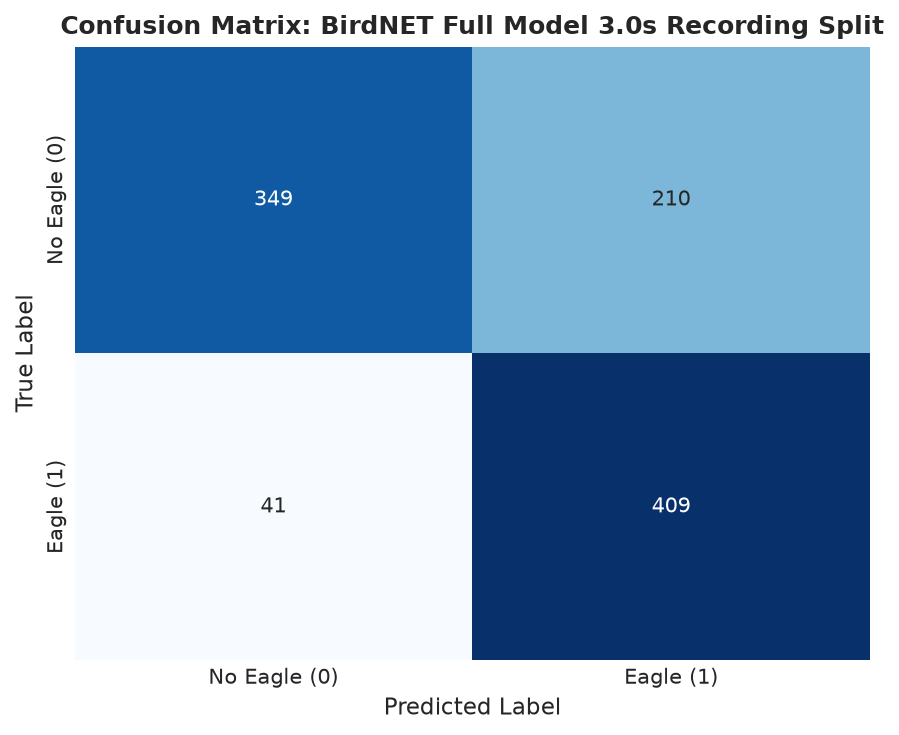

In [9]:
test_idx = SPLITS["Recording Split"]
RESULTS["Recording Split"] = evaluate_predictions(
    y_all[test_idx],
    eagle_conf_all[test_idx],
    "BirdNET Full Model 3.0s Recording Split",
    CM_DIR / "recording-split-confusion-matrix.png",
)


### 9.2. Evaluate on the Test Subset: LOSO - Davao del Sur

EVALUATION RESULTS: BirdNET Full Model 3.0s LOSO - Davao del Sur
BirdNET as distributed, no training. Eagle if the Philippine Eagle confidence >= 0.50.
Accuracy:    0.4784 (47.84%)
Precision:   0.3839 (38.39%)
Recall:      0.8765 (87.65%)
F1-Score:    0.5339 (53.39%)
Specificity: 0.2726 (27.26%)
ROC-AUC:     0.7340
PR-AUC:      0.6874
Confusion:   TN 892 | FP 2380 | FN 209 | TP 1483
              precision    recall  f1-score   support

No Eagle (0)       0.81      0.27      0.41      3272
   Eagle (1)       0.38      0.88      0.53      1692

    accuracy                           0.48      4964
   macro avg       0.60      0.57      0.47      4964
weighted avg       0.66      0.48      0.45      4964

Saved statistics to: outputs/statistics/birdnet-full-model-3s-loso-davao-del-sur-statistics.txt
Saved confusion matrix to: outputs/confusion-matrices/loso-davao-confusion-matrix.png


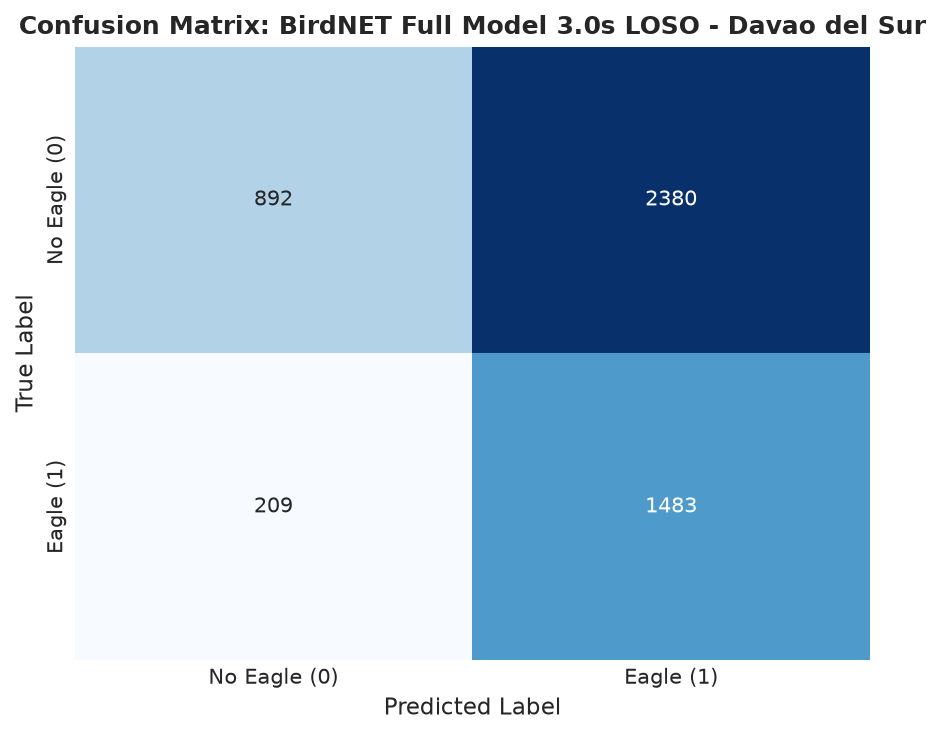

In [10]:
test_idx = SPLITS["LOSO - Davao del Sur"]
RESULTS["LOSO - Davao del Sur"] = evaluate_predictions(
    y_all[test_idx],
    eagle_conf_all[test_idx],
    "BirdNET Full Model 3.0s LOSO - Davao del Sur",
    CM_DIR / "loso-davao-confusion-matrix.png",
)


### 9.3. Evaluate on the Test Subset: LOSO - Cotabato

EVALUATION RESULTS: BirdNET Full Model 3.0s LOSO - Cotabato
BirdNET as distributed, no training. Eagle if the Philippine Eagle confidence >= 0.50.
Accuracy:    0.5785 (57.85%)
Precision:   0.5084 (50.84%)
Recall:      0.9615 (96.15%)
F1-Score:    0.6651 (66.51%)
Specificity: 0.2832 (28.32%)
ROC-AUC:     0.7812
PR-AUC:      0.7402
Confusion:   TN 544 | FP 1377 | FN 57 | TP 1424
              precision    recall  f1-score   support

No Eagle (0)       0.91      0.28      0.43      1921
   Eagle (1)       0.51      0.96      0.67      1481

    accuracy                           0.58      3402
   macro avg       0.71      0.62      0.55      3402
weighted avg       0.73      0.58      0.53      3402

Saved statistics to: outputs/statistics/birdnet-full-model-3s-loso-cotabato-statistics.txt
Saved confusion matrix to: outputs/confusion-matrices/loso-cotabato-confusion-matrix.png


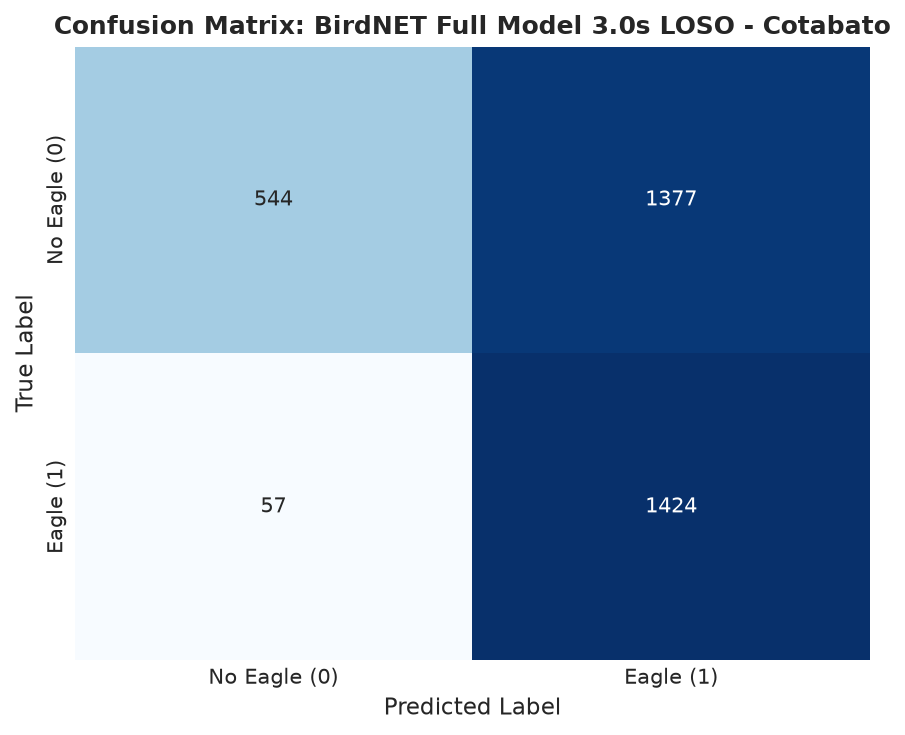

In [11]:
test_idx = SPLITS["LOSO - Cotabato"]
RESULTS["LOSO - Cotabato"] = evaluate_predictions(
    y_all[test_idx],
    eagle_conf_all[test_idx],
    "BirdNET Full Model 3.0s LOSO - Cotabato",
    CM_DIR / "loso-cotabato-confusion-matrix.png",
)


### 9.4. Evaluate on the Test Subset: Minor Sites Held Out

EVALUATION RESULTS: BirdNET Full Model 3.0s Minor Sites Held Out
BirdNET as distributed, no training. Eagle if the Philippine Eagle confidence >= 0.50.
Accuracy:    0.6291 (62.91%)
Precision:   0.6835 (68.35%)
Recall:      0.3293 (32.93%)
F1-Score:    0.4444 (44.44%)
Specificity: 0.8750 (87.50%)
ROC-AUC:     0.8275
PR-AUC:      0.7311
Confusion:   TN 175 | FP 25 | FN 110 | TP 54
              precision    recall  f1-score   support

No Eagle (0)       0.61      0.88      0.72       200
   Eagle (1)       0.68      0.33      0.44       164

    accuracy                           0.63       364
   macro avg       0.65      0.60      0.58       364
weighted avg       0.65      0.63      0.60       364

Saved statistics to: outputs/statistics/birdnet-full-model-3s-minor-sites-held-out-statistics.txt
Saved confusion matrix to: outputs/confusion-matrices/loso-minor-sites-confusion-matrix.png


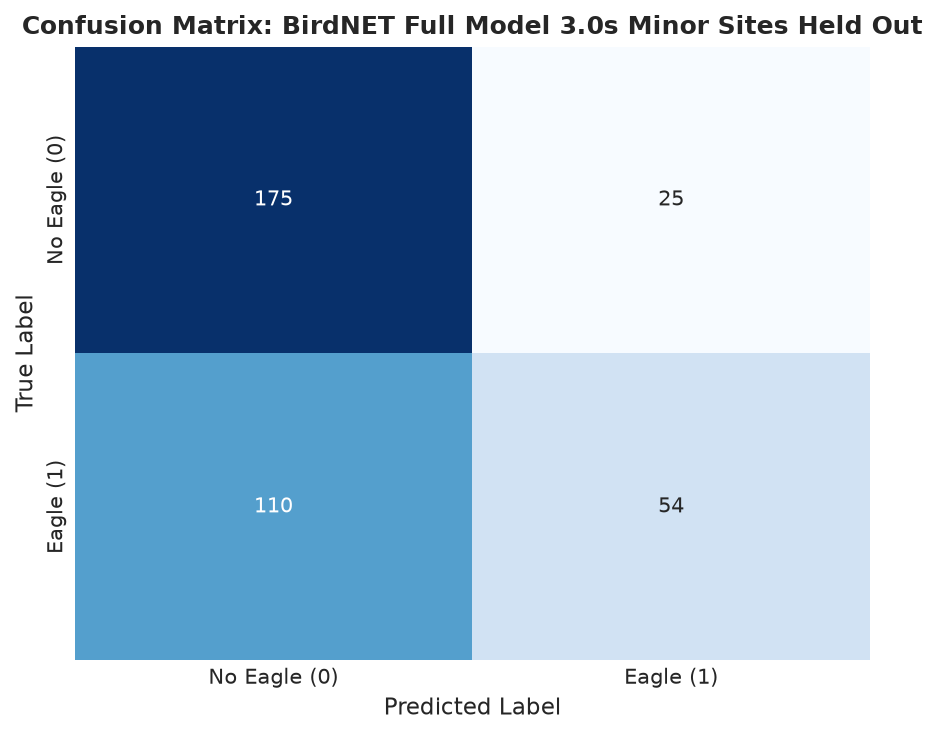

In [12]:
test_idx = SPLITS["Minor Sites Held Out"]
RESULTS["Minor Sites Held Out"] = evaluate_predictions(
    y_all[test_idx],
    eagle_conf_all[test_idx],
    "BirdNET Full Model 3.0s Minor Sites Held Out",
    CM_DIR / "loso-minor-sites-confusion-matrix.png",
)


## 10. Results at Other Decision Thresholds (Recording Split)

The 0.50 threshold is not a BirdNET setting. This table shows how the result changes at lower thresholds. The thresholds are fixed values for reference; none of them was tuned on the data.

In [13]:
test_idx = SPLITS["Recording Split"]
y_true = y_all[test_idx]
conf = eagle_conf_all[test_idx]

threshold_rows = []
for threshold in [0.05, 0.10, 0.25, 0.50, 0.75]:
    y_pred = (conf >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": f"{threshold:.2f}",
        "Accuracy": f"{accuracy_score(y_true, y_pred) * 100:.2f}%",
        "Precision": f"{precision_score(y_true, y_pred, zero_division=0) * 100:.2f}%",
        "Recall": f"{recall_score(y_true, y_pred, zero_division=0) * 100:.2f}%",
        "F1-Score": f"{f1_score(y_true, y_pred, zero_division=0):.4f}",
        "Specificity": f"{tn / (tn + fp) * 100:.2f}%",
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    })
df_thresholds = pd.DataFrame(threshold_rows)
display(df_thresholds)

threshold_text = "\n".join([
    "=" * 100,
    "BIRDNET FULL MODEL AT OTHER DECISION THRESHOLDS (RECORDING SPLIT, TEST SUBSET)",
    "Fixed thresholds for reference. None was tuned on the data. The reported results use 0.50.",
    "=" * 100,
    df_thresholds.to_string(index=False),
])
threshold_path = STATISTICS_DIR / "birdnet-full-model-thresholds.txt"
threshold_path.write_text(threshold_text + "\n")
print(f"Saved threshold table to: {threshold_path.relative_to(EXPERIMENT_DIR)}")


,Threshold,Accuracy,Precision,Recall,F1-Score,Specificity,TN,FP,FN,TP
0,0.05,75.42%,65.03%,97.11%,0.7790,57.96%,324,235,13,437
1,0.10,75.52%,65.31%,96.22%,0.7781,58.86%,329,230,17,433
2,0.25,74.93%,65.18%,94.00%,0.7698,59.57%,333,226,27,423
3,0.50,75.12%,66.07%,90.89%,0.7652,62.43%,349,210,41,409
4,0.75,76.11%,68.37%,86.44%,0.7635,67.80%,379,180,61,389


Saved threshold table to: outputs/statistics/birdnet-full-model-thresholds.txt


## 11. Philippine Eagle Confidence by Window Type (Recording Split)

Saved figure to: outputs/figures/eagle-confidence-distribution.png


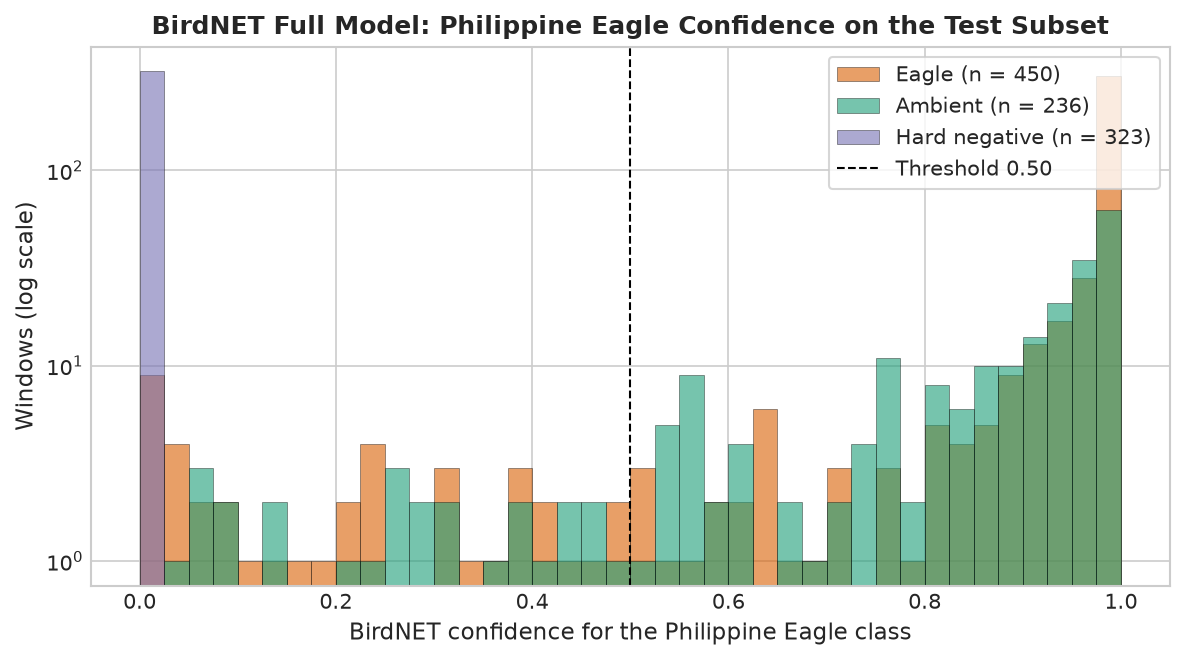

,windows,called_eagle,median_confidence,mean_confidence,called_eagle_pct
group,,,,,
Eagle,450,409,0.9940,0.8904,90.89
Ambient,236,210,0.9274,0.8171,88.98
Hard negative,323,0,0.0000,0.0000,0.00


In [14]:
df_test = df_scored.iloc[SPLITS["Recording Split"]]
group_order = ["Eagle", "Ambient", "Hard negative"]
group_colors = {"Eagle": "#d95f02", "Ambient": "#1b9e77", "Hard negative": "#7570b3"}

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, 1, 41)
for group in group_order:
    values = df_test.loc[df_test["group"] == group, "eagle_confidence"]
    ax.hist(values, bins=bins, alpha=0.6, color=group_colors[group], edgecolor="black", linewidth=0.3, label=f"{group} (n = {len(values)})")
ax.axvline(DECISION_THRESHOLD, color="black", linestyle="--", linewidth=1, label=f"Threshold {DECISION_THRESHOLD:.2f}")
ax.set_yscale("log")
ax.set_xlabel("BirdNET confidence for the Philippine Eagle class")
ax.set_ylabel("Windows (log scale)")
ax.set_title("BirdNET Full Model: Philippine Eagle Confidence on the Test Subset", fontweight="bold")
ax.legend(frameon=True)
plt.tight_layout()
confidence_fig_path = FIGURES_DIR / "eagle-confidence-distribution.png"
fig.savefig(confidence_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {confidence_fig_path.relative_to(EXPERIMENT_DIR)}")
plt.show()

group_summary = df_test.groupby("group").agg(
    windows=("label", "size"),
    called_eagle=("eagle_confidence", lambda v: int((v >= DECISION_THRESHOLD).sum())),
    median_confidence=("eagle_confidence", "median"),
    mean_confidence=("eagle_confidence", "mean"),
).reindex(group_order)
group_summary["called_eagle_pct"] = (100 * group_summary["called_eagle"] / group_summary["windows"]).round(2)
display(group_summary.round(4))


## 12. Species BirdNET Named on the Test Windows (Recording Split)

In [15]:
# The species with the highest BirdNET confidence in each window, for each window type
df_test = df_scored.iloc[SPLITS["Recording Split"]]

species_lines = [
    "=" * 80,
    "SPECIES WITH THE HIGHEST BIRDNET CONFIDENCE (RECORDING SPLIT, TEST SUBSET)",
    "=" * 80,
]
for group in ["Eagle", "Ambient", "Hard negative"]:
    top_named = df_test.loc[df_test["group"] == group, "top_species"].value_counts().head(10)
    total = int((df_test["group"] == group).sum())
    species_lines += ["", f"{group} windows (n = {total}): ten most frequent top species"]
    species_lines += [f"  {name:<40} {count:>5} ({100 * count / total:5.1f}%)" for name, count in top_named.items()]

species_text = "\n".join(species_lines)
print(species_text)
species_path = STATISTICS_DIR / "birdnet-full-model-top-species.txt"
species_path.write_text(species_text + "\n")
print(f"\nSaved to: {species_path.relative_to(EXPERIMENT_DIR)}")


SPECIES WITH THE HIGHEST BIRDNET CONFIDENCE (RECORDING SPLIT, TEST SUBSET)

Eagle windows (n = 450): ten most frequent top species
  Philippine Eagle                           428 ( 95.1%)
  Rufous-tailed Flatbill                       6 (  1.3%)
  Rufous Hornbill                              3 (  0.7%)
  Oriental Honey-buzzard                       3 (  0.7%)
  Philippine Oriole                            2 (  0.4%)
  Long-billed Woodcreeper                      2 (  0.4%)
  Black Cuckoo                                 2 (  0.4%)
  Sunbittern                                   1 (  0.2%)
  Orange-bellied Flowerpecker                  1 (  0.2%)
  Pearl-spotted Owlet                          1 (  0.2%)

Ambient windows (n = 236): ten most frequent top species
  Philippine Eagle                           225 ( 95.3%)
  Philippine Bulbul                            8 (  3.4%)
  Rufous Hornbill                              1 (  0.4%)
  Sykes's Warbler                              1 (  0.4%)

## 13. Export the Performance Summary

In [16]:
summary_rows = []
for split_name, m in RESULTS.items():
    summary_rows.append({
        "Experiment": split_name,
        "Accuracy": f"{m['accuracy'] * 100:.2f}%",
        "Precision": f"{m['precision'] * 100:.2f}%",
        "Recall": f"{m['recall'] * 100:.2f}%",
        "F1-Score": f"{m['f1_score']:.4f}",
        "Specificity": f"{m['specificity'] * 100:.2f}%",
        "ROC-AUC": f"{m['roc_auc']:.4f}",
        "PR-AUC": f"{m['pr_auc']:.4f}",
        "TN": m["tn"], "FP": m["fp"], "FN": m["fn"], "TP": m["tp"],
        "Model Size": f"{BIRDNET_MODEL_SIZE_MB:.1f} MB",
        "Latency (laptop CPU)": f"{MEAN_INFERENCE_MS:.1f} ms",
    })
df_summary = pd.DataFrame(summary_rows)
display(df_summary)

summary_csv_path = OUTPUTS_DIR / "performance-summary.csv"
df_summary.to_csv(summary_csv_path, index=False)

summary_text = "\n".join([
    "=" * 150,
    "BIRDNET FULL MODEL (VERSION 2.4, FP32) WITHOUT TRAINING",
    f"A window is called eagle when the confidence of the BirdNET class '{birdnet_labels[EAGLE_CLASS_INDEX]}' is at least {DECISION_THRESHOLD:.2f}.",
    "Windows are cut from the original recordings at 48 kHz. Test subsets are the same as for the other models.",
    "BirdNET's training data may include some of these recordings.",
    "=" * 150,
    df_summary.to_string(index=False),
])
summary_txt_path = STATISTICS_DIR / "birdnet-full-model-performance-summary.txt"
summary_txt_path.write_text(summary_text + "\n")
print(summary_text)
print(f"\nSaved: {summary_csv_path.relative_to(EXPERIMENT_DIR)}")
print(f"Saved: {summary_txt_path.relative_to(EXPERIMENT_DIR)}")


,Experiment,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP,Model Size,Latency (laptop CPU)
0,Recording Split,75.12%,66.07%,90.89%,0.7652,62.43%,0.8917,0.8722,349,210,41,409,49.3 MB,40.9 ms
1,LOSO - Davao del Sur,47.84%,38.39%,87.65%,0.5339,27.26%,0.7340,0.6874,892,2380,209,1483,49.3 MB,40.9 ms
2,LOSO - Cotabato,57.85%,50.84%,96.15%,0.6651,28.32%,0.7812,0.7402,544,1377,57,1424,49.3 MB,40.9 ms
3,Minor Sites Held Out,62.91%,68.35%,32.93%,0.4444,87.50%,0.8275,0.7311,175,25,110,54,49.3 MB,40.9 ms


BIRDNET FULL MODEL (VERSION 2.4, FP32) WITHOUT TRAINING
A window is called eagle when the confidence of the BirdNET class 'Pithecophaga jefferyi_Philippine Eagle' is at least 0.50.
Windows are cut from the original recordings at 48 kHz. Test subsets are the same as for the other models.
BirdNET's training data may include some of these recordings.
          Experiment Accuracy Precision Recall F1-Score Specificity ROC-AUC PR-AUC  TN   FP  FN   TP Model Size Latency (laptop CPU)
     Recording Split   75.12%    66.07% 90.89%   0.7652      62.43%  0.8917 0.8722 349  210  41  409    49.3 MB              40.9 ms
LOSO - Davao del Sur   47.84%    38.39% 87.65%   0.5339      27.26%  0.7340 0.6874 892 2380 209 1483    49.3 MB              40.9 ms
     LOSO - Cotabato   57.85%    50.84% 96.15%   0.6651      28.32%  0.7812 0.7402 544 1377  57 1424    49.3 MB              40.9 ms
Minor Sites Held Out   62.91%    68.35% 32.93%   0.4444      87.50%  0.8275 0.7311 175   25 110   54    49.3 MB       